<a href="https://colab.research.google.com/github/deboraluz/deboraluz/blob/main/Profissao_Cientista_de_Dados_M21_Pratique.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MÓDULO 21 - Projeto de Credit Score - Árvore de Decisão**


No módulo 17, vocês realizaram a primeira etapa do projeto de crédito de vocês. Então fizeram o tratamendo dos dados, balancearam as classes, transformaram as variáveis categóricas e separam base de treino e teste. Já no módulo 14, aplicaram a base já tratada o algoritmo de Naive Bayes, onde avaliaram os resultados das previsões. Nesse módulo aplicaremos a nossa base o algoritmo da árvore de decisão.

In [7]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1) Comece carregando as bases de treino (X e y) e teste (X e y).
Verifique se o número de linhas condiz, se as variáveis estão corretas sendo apenas a de score para y e as demais nas bases de X e por último, se Y está balanceada no teste.

In [8]:
X_train = pd.read_csv('X_train_balanced.csv')
X_test = pd.read_csv('X_test.csv')
y_train = pd.read_csv('y_train_balanced.csv').iloc[:, 0]
y_test = pd.read_csv('y_test.csv').iloc[:, 0]

print('X_train:', X_train.shape, '| X_test:', X_test.shape)
print('y_train:', y_train.shape, '| y_test:', y_test.shape)
print('Variáveis de X:', X_train.columns.tolist())
print('Valores ausentes:', X_train.isna().sum().sum(), X_test.isna().sum().sum())
print('Distribuição y_train:')
print(y_train.value_counts(), '\\nProporção:')
print(y_train.value_counts(normalize=True))
print('Distribuição y_test:')
print(y_test.value_counts(), '\\nProporção:')
print(y_test.value_counts(normalize=True))


X_train: (117950, 10) | X_test: (24927, 10)
y_train: (117950,) | y_test: (24927,)
Variáveis de X: ['Credit_Score', 'Idade', 'Tempo_Credito', 'Balanco', 'Qtd_Produtos', 'Possui_Cartao', 'Membro_Ativo', 'Salario_Anual', 'Genero_encoded', 'Pais_encoded']
Valores ausentes: 0 0
Distribuição y_train:
Churn
1.0    58975
0.0    58975
Name: count, dtype: int64 \nProporção:
Churn
1.0    0.5
0.0    0.5
Name: proportion, dtype: float64
Distribuição y_test:
Churn
0.0    19649
1.0     5278
Name: count, dtype: int64 \nProporção:
Churn
0.0    0.788262
1.0    0.211738
Name: proportion, dtype: float64


In [ ]:

print("Colunas de treino:")
print(X_train.columns.tolist())

print("\nDistribuição dos scores:")
print(X_train["Credit_Score"].describe())

print("\nMenores scores:")
print(sorted(X_train["Credit_Score"].unique())[:20])

print("\nMaiores scores:")
print(sorted(X_train["Credit_Score"].unique())[-20:])


Colunas de treino:
['Credit_Score', 'Idade', 'Tempo_Credito', 'Balanco', 'Qtd_Produtos', 'Possui_Cartao', 'Membro_Ativo', 'Salario_Anual', 'Genero_encoded', 'Pais_encoded']

Distribuição dos scores:
count    117950.000000
mean        655.049682
std          77.275411
min         350.000000
25%         598.000000
50%         656.000000
75%         708.000000
max         850.000000
Name: Credit_Score, dtype: float64

Menores scores:
[np.int64(350), np.int64(358), np.int64(359), np.int64(361), np.int64(363), np.int64(367), np.int64(376), np.int64(382), np.int64(383), np.int64(386), np.int64(388), np.int64(393), np.int64(397), np.int64(399), np.int64(401), np.int64(404), np.int64(405), np.int64(407), np.int64(408), np.int64(410)]

Maiores scores:
[np.int64(831), np.int64(832), np.int64(833), np.int64(834), np.int64(835), np.int64(836), np.int64(837), np.int64(838), np.int64(839), np.int64(840), np.int64(841), np.int64(842), np.int64(843), np.int64(844), np.int64(845), np.int64(846), np.int

# 2) Explique com suas palavras, qual o passo a passo para a aplicação do algoritmo da árvore de decisão, não esqueça de citar a etapa de avaliação do modelo e também como podemos melhorar nosso modelo.

A árvore de decisão aprende regras sequenciais a partir das variáveis de entrada para separar as classes do alvo. Primeiro, os dados precisam estar tratados e divididos em treino e teste; depois, o algoritmo escolhe divisões que reduzem a impureza dos grupos (neste exercício, pelo critério Gini). O modelo é ajustado somente com os dados de treino. Em seguida, fazemos previsões no conjunto de teste, que não foi usado no ajuste, e avaliamos métricas como acurácia, matriz de confusão, precisão, recall e F1. Comparar treino e teste ajuda a identificar sobreajuste. O modelo pode ser melhorado limitando `max_depth`, ajustando `min_samples_split` e `min_samples_leaf`, usando validação cruzada e busca de hiperparâmetros, e avaliando métricas adequadas ao desbalanceamento das classes. Também é importante comparar o recall/F1 da classe minoritária, e não apenas a acurácia.

# 3) Aplique o algortimo da árvore de decisão aos dados de treinamento, utilizando critério de Gini e random state = 0.
Traga a acurácia para o modelo com os dados de treino.

In [9]:
# Modelo original: critério Gini e random_state=0
arvore = DecisionTreeClassifier(criterion='gini', random_state=0)
arvore.fit(X_train, y_train)

pred_train = arvore.predict(X_train)
acc_train = accuracy_score(y_train, pred_train)
print(f'Acurácia treino: {acc_train:.4f}')
print(f'Profundidade: {arvore.get_depth()}')
print(f'Número de folhas: {arvore.get_n_leaves()}')

Acurácia treino: 0.9997
Profundidade: 39
Número de folhas: 13423


# 4) Aplique o modelo aos dados de teste e realize a avaliação dos resultados. Não se esqueça de avaliar com as suas palavras e comparar o desempenho da base treino com a teste.

In [10]:
# Avaliação no conjunto de teste
pred_test = arvore.predict(X_test)
acc_test = accuracy_score(y_test, pred_test)
print(f'Acurácia teste: {acc_test:.4f}')
print('Matriz de confusão:')
print(confusion_matrix(y_test, pred_test))
print('Relatório de classificação:')
print(classification_report(y_test, pred_test, zero_division=0))

Acurácia teste: 0.7900
Matriz de confusão:
[[16741  2908]
 [ 2327  2951]]
Relatório de classificação:
              precision    recall  f1-score   support

         0.0       0.88      0.85      0.86     19649
         1.0       0.50      0.56      0.53      5278

    accuracy                           0.79     24927
   macro avg       0.69      0.71      0.70     24927
weighted avg       0.80      0.79      0.79     24927



Existe uma diferença expressiva entre a acurácia de treino (99,97%) e a de teste (79,00%). Isso sinaliza um claro overfitting (superajuste): a árvore decorou os dados de treinamento (alcançando 13.423 folhas), perdendo capacidade de generalização ao lidar com dados não vistos.

# 5) Plote a árvore de decisão.
É possível fazer uma avaliação visual? Qual a profundidade da árvore?

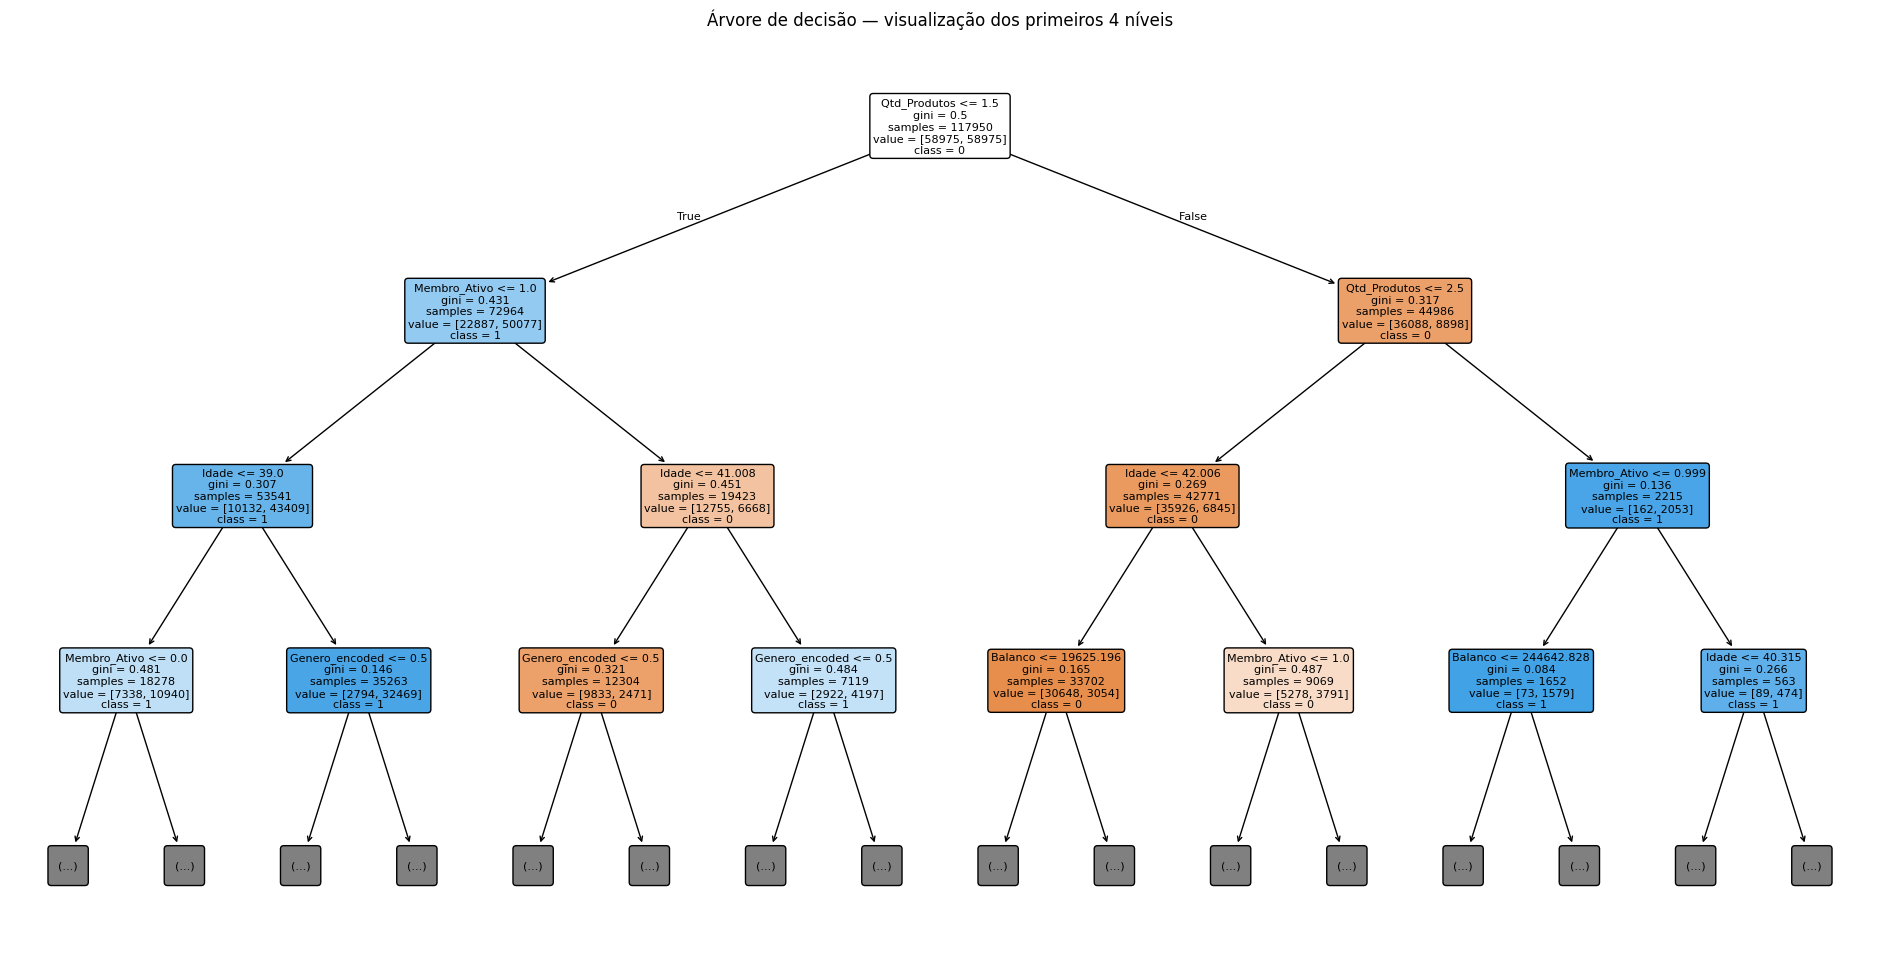

Profundidade total da árvore: 39
A árvore tem profundidade alta e muitas folhas, o que pode indicar sobreajuste.


In [11]:
# A árvore completa é muito grande; exibimos os primeiros níveis para leitura.
plt.figure(figsize=(24, 12))
plot_tree(arvore, feature_names=X_train.columns, class_names=['0', '1'],
          filled=True, rounded=True, max_depth=3, fontsize=8)
plt.title('Árvore de decisão — visualização dos primeiros 4 níveis')
plt.show()
print('Profundidade total da árvore:', arvore.get_depth())
print('A árvore tem profundidade alta e muitas folhas, o que pode indicar sobreajuste.')

# 6) Identifique as 2 principais features do modelo.


,Importância
Qtd_Produtos,0.267402
Idade,0.195928
Membro_Ativo,0.182026
Credit_Score,0.104225
Balanco,0.080774
Tempo_Credito,0.045473
Salario_Anual,0.042444
Possui_Cartao,0.034223
Genero_encoded,0.031131
Pais_encoded,0.016374


Duas principais features: ['Qtd_Produtos', 'Idade']


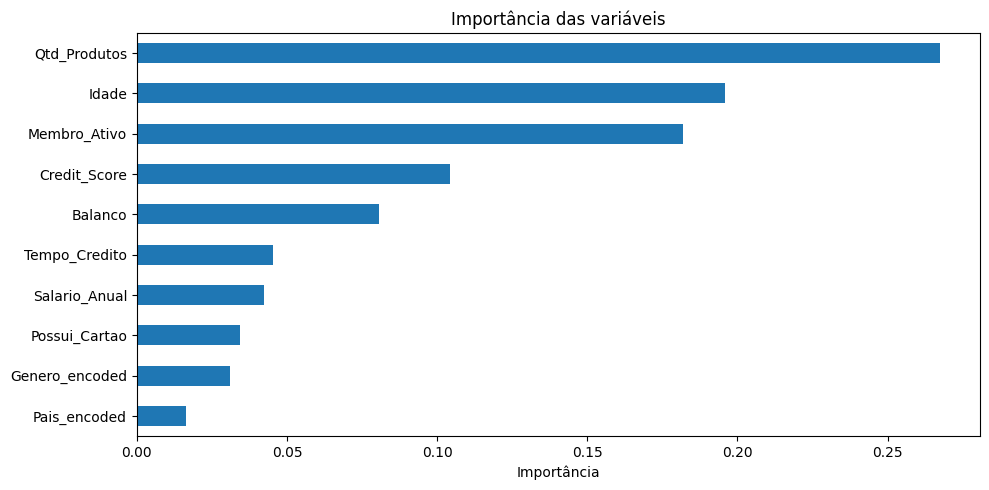

In [12]:
# Importância das variáveis e seleção das duas principais features
importancias = pd.Series(arvore.feature_importances_, index=X_train.columns).sort_values(ascending=False)
display(importancias.to_frame('Importância'))
duas_features = importancias.head(2).index.tolist()
print('Duas principais features:', duas_features)

plt.figure(figsize=(10, 5))
importancias.sort_values().plot(kind='barh')
plt.xlabel('Importância')
plt.title('Importância das variáveis')
plt.tight_layout()
plt.show()

# 7) Rode um modelo de árvore de decisão apenas com as 2 principais features encontradas. E avalie os resultados. Para você o desempenho da árvore está melhor que o modelo anterior? Justifique.

In [13]:
# Novo modelo usando somente as duas features mais importantes
X_train_2 = X_train[duas_features]
X_test_2 = X_test[duas_features]

arvore_2 = DecisionTreeClassifier(criterion='gini', random_state=0)
arvore_2.fit(X_train_2, y_train)

pred_train_2 = arvore_2.predict(X_train_2)
pred_test_2 = arvore_2.predict(X_test_2)

print(f'Acurácia treino (10 features): {accuracy_score(y_train, pred_train):.4f}')
print(f'Acurácia teste (10 features): {accuracy_score(y_test, pred_test):.4f}')
print(f'Acurácia treino (2 features): {accuracy_score(y_train, pred_train_2):.4f}')
print(f'Acurácia teste (2 features): {accuracy_score(y_test, pred_test_2):.4f}')
print('Relatório de classificação - modelo com 2 features:')
print(classification_report(y_test, pred_test_2, zero_division=0))

Acurácia treino (10 features): 0.9997
Acurácia teste (10 features): 0.7900
Acurácia treino (2 features): 0.8888
Acurácia teste (2 features): 0.8451
Relatório de classificação - modelo com 2 features:
              precision    recall  f1-score   support

         0.0       0.88      0.93      0.90     19649
         1.0       0.67      0.52      0.59      5278

    accuracy                           0.85     24927
   macro avg       0.78      0.73      0.75     24927
weighted avg       0.84      0.85      0.84     24927



O modelo com apenas 2 features apresentou um desempenho superior e mais consistente.

Redução do Overfitting: A diferença entre treino e teste caiu de ~21 pontos percentuais no modelo original (99,97% vs 79,00%) para apenas ~4,3 pontos percentuais no modelo reduzido (88,88% vs 84,51%).

Ganho de Acurácia no Teste: A acurácia nos dados reais de teste subiu de 79,00% para 84,51%.

Simplicidade e Interpretabilidade: O modelo ficou drasticamente mais simples, reduzindo o ruído trazido por variáveis secundárias e melhorando a generalização.


# 8) Compare os resultados obtidos com a árvore de decisão com os resultados do Naive Bayes (Exercício módulo 20). Qual parece ter se adequado melhor aos dados e tem melhores resultados de avaliação? Justifique.

A árvore de decisão com apenas duas features apresentou os melhores resultados, com acurácia de teste de 84,51%, seguida pela árvore completa, com 79,00%. Já o Naive Bayes obteve acurácia de 55,53% e recall macro de 58,92%.

Assim, a árvore de decisão com duas features parece ter se adequado melhor aos dados, apresentando maior capacidade de generalização no conjunto de teste. Além disso, a seleção das duas variáveis mais importantes simplificou o modelo e melhorou sua acurácia. Entretanto, seria interessante comparar também o recall macro e o F1-score dos modelos para uma avaliação mais completa, especialmente devido ao desbalanceamento da base de teste.